# Task 5 — Association Rule Mining

Notebook ini menggunakan langsung **keempat CSV frequent itemsets Task 4 dari dataset penuh** pada minimum support 0,1%, 0,5%, 1%, dan 2%; FP-Growth tidak dijalankan ulang. Association rules dibangkitkan terpisah untuk setiap ambang dengan minimum confidence 50%. Semua input berasal dari `data/results/`—tidak ada pembacaan parquet. Jumlah transaksi Author-Based diambil dari ringkasan Task 3 agar support dan lift dihitung dengan denominator yang benar.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

cwd = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in (cwd, *cwd.parents)
     if (path / "src" / "association_rules.py").is_file() and (path / "data").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Folder proyek tidak ditemukan dari current working directory.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.association_rules import generate_rules

RESULTS_DIR = PROJECT_ROOT / "data" / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

MIN_SUPPORTS = [0.001, 0.005, 0.01, 0.02]
MIN_CONFIDENCE = 0.50
ITEMSET_FILES = {
    min_support: RESULTS_DIR / f"task4_itemsets_minsup_{min_support}.csv"
    for min_support in MIN_SUPPORTS
}
TASK3_SUMMARY_PATH = RESULTS_DIR / "task3_summary.csv"
print(f"Project root: {PROJECT_ROOT}")
print(f"Minimum confidence: {MIN_CONFIDENCE:.0%}")
for min_support, path in ITEMSET_FILES.items():
    print(f"min_support={min_support:.1%}: {path.relative_to(PROJECT_ROOT)}")

Project root: D:\IF4041-project-data-mining
Minimum confidence: 50%
min_support=0.1%: data\results\task4_itemsets_minsup_0.001.csv
min_support=0.5%: data\results\task4_itemsets_minsup_0.005.csv
min_support=1.0%: data\results\task4_itemsets_minsup_0.01.csv
min_support=2.0%: data\results\task4_itemsets_minsup_0.02.csv


## 1. Muat empat hasil itemsets Task 4

Kolom `itemset` pada CSV Task 4 berisi kode venue dipisahkan koma, sedangkan `support_count` adalah jumlah transaksi absolut. Denominator dibaca dari `task3_summary.csv` (baris Author-Based), sehingga notebook ini tidak perlu memuat transaksi atau parquet.

In [2]:
missing_files = [str(path) for path in [*ITEMSET_FILES.values(), TASK3_SUMMARY_PATH]
                 if not path.is_file()]
if missing_files:
    raise FileNotFoundError("File input tidak ditemukan:\n" + "\n".join(missing_files))

task3_summary = pd.read_csv(TASK3_SUMMARY_PATH)
author_rows = task3_summary.loc[
    task3_summary["representasi"].astype(str).str.strip().eq("Author-Based"),
    "jumlah_transaksi",
]
if len(author_rows) != 1:
    raise ValueError("task3_summary.csv harus memiliki tepat satu baris Author-Based.")
total_transactions = int(author_rows.iloc[0])
if total_transactions <= 0:
    raise ValueError("Jumlah transaksi Author-Based harus lebih besar dari 0.")
print(f"Jumlah transaksi Author-Based dari Task 3: {total_transactions:,}")

def load_frequent_itemsets(path):
    table = pd.read_csv(path)
    required_columns = {"itemset", "k", "support_count"}
    missing_columns = required_columns - set(table.columns)
    if missing_columns:
        raise ValueError(f"Kolom CSV {path.name} tidak lengkap: {sorted(missing_columns)}")

    frequent_itemsets = {}
    for row in table.itertuples(index=False):
        items = frozenset(code.strip() for code in str(row.itemset).split(",") if code.strip())
        if not items or len(items) != int(row.k):
            raise ValueError(f"Itemset tidak valid pada {path.name}: {row.itemset!r}")
        count = int(row.support_count)
        if count <= 0 or items in frequent_itemsets:
            raise ValueError(f"Support count/itemset duplikat tidak valid pada {path.name}: {row.itemset!r}")
        frequent_itemsets[items] = count
    return frequent_itemsets

frequent_itemsets_by_support = {
    min_support: load_frequent_itemsets(path)
    for min_support, path in ITEMSET_FILES.items()
}
for min_support, itemsets in frequent_itemsets_by_support.items():
    print(f"min_support={min_support:.1%}: {len(itemsets):,} itemsets "
          f"({sum(len(itemset) == 1 for itemset in itemsets)} singleton, "
          f"{sum(len(itemset) >= 2 for itemset in itemsets)} ukuran >= 2)")

Jumlah transaksi Author-Based dari Task 3: 1,821,649
min_support=0.1%: 1,514 itemsets (574 singleton, 940 ukuran >= 2)
min_support=0.5%: 88 itemsets (66 singleton, 22 ukuran >= 2)
min_support=1.0%: 30 itemsets (29 singleton, 1 ukuran >= 2)
min_support=2.0%: 6 itemsets (6 singleton, 0 ukuran >= 2)


## 2. Bangkitkan association rules

`generate_rules` dijalankan satu kali untuk setiap hasil Task 4. Rules dari minimum support berbeda diberi label ambangnya agar tabel dan perbandingan tidak mencampur eksperimen.

In [3]:
def format_venues(itemset):
    return ", ".join(sorted(itemset))

rules_by_support = {}
summary_rows = []
all_rules_rows = []
top10_rows = []

for min_support, frequent_itemsets in frequent_itemsets_by_support.items():
    rules = generate_rules(
        frequent_itemsets,
        total_transactions=total_transactions,
        min_confidence=MIN_CONFIDENCE,
    )
    rules_by_support[min_support] = rules

    rules_display = rules.copy()
    if not rules_display.empty:
        rules_display["antecedents"] = rules_display["antecedents"].map(format_venues)
        rules_display["consequents"] = rules_display["consequents"].map(format_venues)
        rules_display.insert(0, "min_support", min_support)
        all_rules_rows.extend(rules_display.to_dict("records"))

        top10 = rules_display.head(10).copy()
        top10.insert(0, "rank_by_lift", range(1, len(top10) + 1))
        top10_rows.extend(top10.to_dict("records"))
    else:
        top10 = pd.DataFrame(columns=[
            "rank_by_lift", "min_support", "antecedents", "consequents",
            "support", "confidence", "lift",
        ])

    summary_rows.append({
        "min_support": min_support,
        "frequent_itemsets": len(frequent_itemsets),
        "association_rules": len(rules),
        "top_rule_lift": float(rules.iloc[0]["lift"]) if not rules.empty else None,
    })
    print(f"min_support={min_support:.1%}: {len(rules):,} rules "
          f"(confidence >= {MIN_CONFIDENCE:.0%})")
    print(f"Top rules by lift for min_support={min_support:.1%}:")
    display(top10)

all_rules_display = pd.DataFrame(all_rules_rows, columns=[
    "min_support", "antecedents", "consequents", "support", "confidence", "lift",
])
top10_by_support = pd.DataFrame(top10_rows, columns=[
    "rank_by_lift", "min_support", "antecedents", "consequents",
    "support", "confidence", "lift",
])
summary_df = pd.DataFrame(summary_rows)

all_rules_path = RESULTS_DIR / "task5_association_rules.csv"
top10_path = RESULTS_DIR / "task5_top10_rules_by_lift.csv"
summary_path = RESULTS_DIR / "task5_summary.csv"
all_rules_display.to_csv(all_rules_path, index=False)
top10_by_support.to_csv(top10_path, index=False)
summary_df.to_csv(summary_path, index=False)
print(f"Seluruh rules: {all_rules_path}")
print(f"Top-10 per minimum support: {top10_path}")
print(f"Ringkasan: {summary_path}")

min_support=0.1%: 1,387 rules (confidence >= 50%)
Top rules by lift for min_support=0.1%:


,rank_by_lift,min_support,antecedents,consequents,support,confidence,lift
0,1,0.001,"eccv, mm, nips","aaai, cvpr, iccv",0.001003,0.612471,172.256690
1,2,0.001,"cvpr, eccv, icml","iccv, iclr, nips",0.001015,0.502309,171.804538
2,3,0.001,"cvpr, iccv, icml, nips","eccv, iclr",0.001015,0.513897,159.369977
3,4,0.001,"cvpr, eccv, icml, nips","iccv, iclr",0.001015,0.591113,157.288863
4,5,0.001,"eccv, iccv, icml","cvpr, iclr, nips",0.001015,0.613674,156.196559
5,6,0.001,"iclr, naacl","acl, emnlp, nips",0.001052,0.503811,152.452890
6,7,0.001,"cvpr, iccv, mm, nips","aaai, eccv",0.001003,0.575071,147.650062
7,8,0.001,"emnlp, naacl, nips","acl, iclr",0.001052,0.545843,146.247100
8,9,0.001,"cvpr, eccv, mm, nips","aaai, iccv",0.001003,0.684526,145.435756
9,10,0.001,"cvpr, eccv, icml","iccv, iclr",0.001083,0.535996,142.622838


min_support=0.5%: 7 rules (confidence >= 50%)
Top rules by lift for min_support=0.5%:


,rank_by_lift,min_support,antecedents,consequents,support,confidence,lift
0,1,0.005,"iclr, nips",icml,0.005716,0.583296,33.313286
1,2,0.005,"icml, nips",iclr,0.005716,0.562774,32.912003
2,3,0.005,"iclr, icml",nips,0.005716,0.804279,25.347993
3,4,0.005,eccv,cvpr,0.007549,0.582934,22.278899
4,5,0.005,iccv,cvpr,0.008476,0.570263,21.794609
5,6,0.005,icml,nips,0.010157,0.580104,18.282803
6,7,0.005,iclr,nips,0.009800,0.573116,18.062574


min_support=1.0%: 1 rules (confidence >= 50%)
Top rules by lift for min_support=1.0%:


,rank_by_lift,min_support,antecedents,consequents,support,confidence,lift
0,1,0.01,icml,nips,0.010157,0.580104,18.282803


min_support=2.0%: 0 rules (confidence >= 50%)
Top rules by lift for min_support=2.0%:


,rank_by_lift,min_support,antecedents,consequents,support,confidence,lift


Seluruh rules: D:\IF4041-project-data-mining\data\results\task5_association_rules.csv
Top-10 per minimum support: D:\IF4041-project-data-mining\data\results\task5_top10_rules_by_lift.csv
Ringkasan: D:\IF4041-project-data-mining\data\results\task5_summary.csv


## 3. Apakah support tinggi selalu berarti lift tinggi?

Perbandingan top-10 support dan top-10 lift dihitung **di dalam setiap minimum support**, bukan dengan mencampurkan empat eksperimen. Korelasi Spearman merangkum hubungan peringkat support dan lift; grafik memperlihatkan sebaran rule yang dihasilkan dari tiap file Task 4.

,min_support,frequent_itemsets,association_rules,top_rule_lift
0,0.001,1514,1387,172.256690
1,0.005,88,7,33.313286
2,0.010,30,1,18.282803
3,0.020,6,0,NaN


,min_support,rule_count,top10_support_lift_overlap,spearman_support_lift
0,0.001,1387,0,-0.209116
1,0.005,7,7,-0.926562
2,0.010,1,1,NaN
3,0.020,0,0,NaN


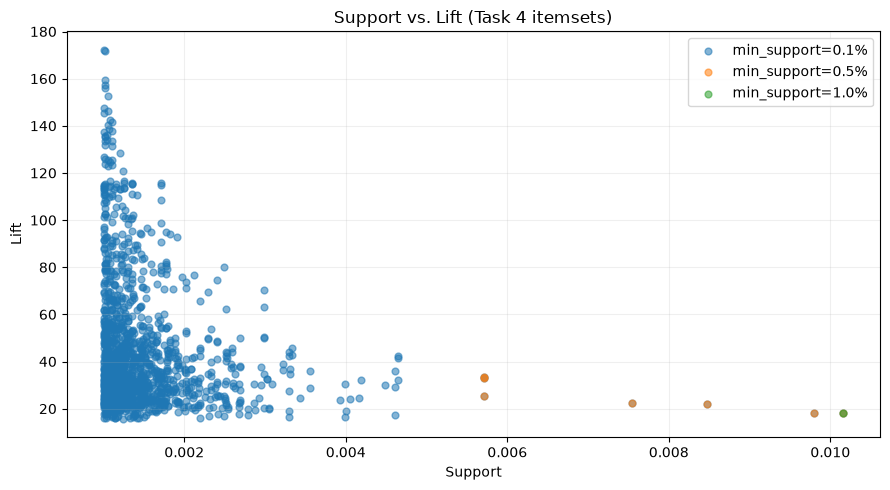

Perbandingan: D:\IF4041-project-data-mining\data\results\task5_support_lift_comparison.csv
Grafik: D:\IF4041-project-data-mining\figures\task5_support_vs_lift.png


In [4]:
comparison_rows = []
for min_support, rules in rules_by_support.items():
    if rules.empty:
        comparison_rows.append({
            "min_support": min_support,
            "rule_count": 0,
            "top10_support_lift_overlap": 0,
            "spearman_support_lift": None,
        })
        continue

    top_support = rules.nlargest(10, "support")
    top_lift = rules.head(10)
    support_keys = set(zip(top_support["antecedents"], top_support["consequents"]))
    lift_keys = set(zip(top_lift["antecedents"], top_lift["consequents"]))
    spearman = (
        rules["support"].rank().corr(rules["lift"].rank())
        if len(rules) > 1 else None
    )
    comparison_rows.append({
        "min_support": min_support,
        "rule_count": len(rules),
        "top10_support_lift_overlap": len(support_keys & lift_keys),
        "spearman_support_lift": spearman,
    })

comparison_df = pd.DataFrame(comparison_rows)
comparison_path = RESULTS_DIR / "task5_support_lift_comparison.csv"
comparison_df.to_csv(comparison_path, index=False)
display(summary_df)
display(comparison_df)

fig, ax = plt.subplots(figsize=(9, 5))
for min_support, rules in rules_by_support.items():
    if not rules.empty:
        ax.scatter(
            rules["support"], rules["lift"], alpha=0.55, s=24,
            label=f"min_support={min_support:.1%}",
        )
ax.set(title="Support vs. Lift (Task 4 itemsets)", xlabel="Support", ylabel="Lift")
ax.legend()
ax.grid(alpha=0.2)
fig.tight_layout()
figure_path = FIGURES_DIR / "task5_support_vs_lift.png"
fig.savefig(figure_path, dpi=160)
plt.show()
print(f"Perbandingan: {comparison_path}")
print(f"Grafik: {figure_path}")

## 4. Interpretasi

- **Support** adalah proporsi author yang memuat semua venue dalam suatu rule; **confidence** adalah proporsi author pada antecedent yang juga memuat consequent; **lift** membandingkan confidence dengan support consequent. Lift di atas 1 mengindikasikan asosiasi positif terhadap baseline independen.
- Top-10 lift ditampilkan untuk setiap nilai minimum support. Rule dengan lift tinggi dapat memiliki support rendah karena pola tersebut jarang secara keseluruhan tetapi relatif kuat pada kelompok author yang memenuhi antecedent. Karena itu, bandingkan support, confidence, dan lift bersama-sama.
- Pada ambang yang lebih tinggi, jumlah itemsets (dan rules) biasanya lebih sedikit. Jika CSV Task 4 hanya berisi singleton pada suatu ambang, tidak ada subset berukuran dua untuk membentuk association rule; notebook menampilkan nol rules untuk kasus tersebut.
- Rules menggambarkan ko-kemunculan venue pada riwayat publikasi author, bukan hubungan sebab-akibat atau bukti bahwa publikasi pada satu venue menyebabkan publikasi pada venue lain.